<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Loading-Packages" data-toc-modified-id="Loading-Packages-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Loading Packages</a></span></li><li><span><a href="#Functions" data-toc-modified-id="Functions-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Functions</a></span></li><li><span><a href="#Data-Cleaning" data-toc-modified-id="Data-Cleaning-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Data Cleaning</a></span><ul class="toc-item"><li><span><a href="#Analysis---Average-Maximum-Distance" data-toc-modified-id="Analysis---Average-Maximum-Distance-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Analysis - Average Maximum Distance</a></span></li></ul></li><li><span><a href="#Plots" data-toc-modified-id="Plots-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Plots</a></span><ul class="toc-item"><li><span><a href="#Lineplot" data-toc-modified-id="Lineplot-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Lineplot</a></span></li><li><span><a href="#Boxplot---Distribution-of-Maximum-Distance" data-toc-modified-id="Boxplot---Distribution-of-Maximum-Distance-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Boxplot - Distribution of Maximum Distance</a></span></li><li><span><a href="#Boxplot---Distribution-of-Weighted-Average" data-toc-modified-id="Boxplot---Distribution-of-Weighted-Average-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Boxplot - Distribution of Weighted Average</a></span></li><li><span><a href="#Violinplot---Distribution-of-Phototactic-Rate-across-Strain-Types" data-toc-modified-id="Violinplot---Distribution-of-Phototactic-Rate-across-Strain-Types-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Violinplot - Distribution of Phototactic Rate across Strain Types</a></span></li></ul></li><li><span><a href="#Statistical-Difference-Testing" data-toc-modified-id="Statistical-Difference-Testing-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Statistical Difference Testing</a></span><ul class="toc-item"><li><span><a href="#Levene's-Test" data-toc-modified-id="Levene's-Test-5.1"><span class="toc-item-num">5.1&nbsp;&nbsp;</span>Levene's Test</a></span></li><li><span><a href="#Kruskal-Wallis-Test" data-toc-modified-id="Kruskal-Wallis-Test-5.2"><span class="toc-item-num">5.2&nbsp;&nbsp;</span>Kruskal-Wallis Test</a></span></li><li><span><a href="#Parametric" data-toc-modified-id="Parametric-5.3"><span class="toc-item-num">5.3&nbsp;&nbsp;</span>Parametric</a></span></li><li><span><a href="#Non-Parametric" data-toc-modified-id="Non-Parametric-5.4"><span class="toc-item-num">5.4&nbsp;&nbsp;</span>Non-Parametric</a></span></li></ul></li><li><span><a href="#Data---Carbone-et-al.-2016" data-toc-modified-id="Data---Carbone-et-al.-2016-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Data - Carbone et al. 2016</a></span></li></ul></div>

# Loading Packages

In [1]:
import os
import csv
import natsort
import sklearn
import statistics
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from natsort import natsorted
import matplotlib.pyplot as plt
from itertools import combinations
import statsmodels.stats.multicomp
import gffpandas.gffpandas as gffpd
from sklearn.metrics import r2_score
from scipy.stats import mannwhitneyu
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
stats.junk = lambda chisq, df: stats.chi2.sf(chisq, df)
from statsmodels.stats.multicomp import pairwise_tukeyhsd
%load_ext rpy2.ipython

# Functions

In [2]:
def upload_file(file):
    dic = {}
    length = len(pd.read_excel(file, sheet_name = None))
    for sheet in [i for i in range(0, length)]:
        a = pd.read_excel(file, sheet_name = sheet)
        a.columns = [i for i in range(len(a.columns))]
        name = a.loc[21, [3, 4]].tolist()
        sample1 = a.iloc[[24, 26, 28], [i for i in range(2, 14, 1)]]
        sample2 = a.iloc[[32, 34, 36], [i for i in range(2, 14, 1)]]

        s1 = []
        for i in sample1.index:
            s1 += sample1.loc[i].tolist()
        s1.reverse()
        s1 = list(filter(lambda x: x >= 0.05, s1))
        s2 = []
        for i in sample2.index:
            s2 += sample2.loc[i].tolist()
        s2.reverse()
        s2 = list(filter(lambda x: x >= 0.05, s2))
        dic[name[0]] = s1
        dic[name[1]] = s2
    motility_assay = pd.DataFrame(dict([ (k,pd.Series(v)) for k,v in dic.items() ]))
    motility_assay = motility_assay.reindex(natsorted(motility_assay.columns), axis=1)
    return motility_assay

In [34]:
def upload_file_lineplot(file):
    dic = {}
    length = len(pd.read_excel(file, sheet_name = None))
    for sheet in [i for i in range(0, length)]:
        a = pd.read_excel(file, sheet_name = sheet)
        a.columns = [i for i in range(len(a.columns))]
        name = a.loc[21, [3, 4]].tolist()
        sample1 = a.iloc[[24, 26, 28], [i for i in range(2, 14, 1)]]
        sample2 = a.iloc[[32, 34, 36], [i for i in range(2, 14, 1)]]

        s1 = []
        for i in sample1.index:
            s1 += sample1.loc[i].tolist()
        s1.reverse()
        s1 = list(filter(lambda x: x >= 0.05, s1))
        s2 = []
        for i in sample2.index:
            s2 += sample2.loc[i].tolist()
        s2.reverse()
        s2 = list(filter(lambda x: x >= 0.05, s2))
        dic[name[0]] = s1
        dic[name[1]] = s2
    motility_assay = pd.DataFrame(dict([ (k,pd.Series(v)) for k,v in dic.items() ]))
    motility_assay = motility_assay.reindex(natsorted(motility_assay.columns), axis=1)

    second_file_path = "/research/projects/chlamydomonas/PhototacticRate/data/Distance_df.xlsx"
    second_excel_file = pd.ExcelFile(second_file_path)
    second_sheet_data = second_excel_file.parse('Sheet1')
    distance_column = second_sheet_data
    
    motility_assay.insert(0, 'Distance (cm)', distance_column)

    return motility_assay

In [35]:
def motility_stats(data, blank):
    ''' This function finds the maximum, average and median distance travelled by each strain. It requires a blank spec
    reading at OD 680 to ensure that it can accurately determine the location.'''
    
    blank = blank

    stats = pd.DataFrame()
    data.index = [i for i in range(len(data))]
    data = data.astype(float)

    #### Removing blanks ####
    for strain in data.columns:
        for idx in data[strain].dropna().index:
            try:
                if (data.loc[idx, strain] <= blank and data.loc[idx + 1, strain] <= blank) or (data.loc[idx, strain] <= blank and data.loc[idx - 1, strain] <= blank):
                    data.loc[idx, strain] = 0
            except: continue
    data = data.replace(0, np.nan)

    #### Maximum distance ####
    for strain in data.columns:
        a = data[strain].dropna()
        stats.loc[strain, 'Maximum Distance'] = len(a) * (2/3) # Each well represents a 0.67 cm increase

    #### Weighted average of chlamy ####
    weighted_av = data.copy()
    weighted_av = weighted_av.replace(np.nan, 0)
    weighted_av.index = [i+1 for i in range(len(weighted_av))]

    total = weighted_av.sum(axis = 0)
    for i in weighted_av.index.values:
        weighted_av.loc[i] = weighted_av.loc[i]*(i* (2/3)) ## multipling each spec reading by their respective distance
    weighted_average = weighted_av.sum(axis = 0)/total
    weighted_average.name = 'Weighted Average'

    stats = pd.concat([stats, weighted_average], axis = 1)
    return stats

# Data Cleaning

In [21]:
dir_path = '/research/projects/chlamydomonas/PhototacticRate/data/Motility_Assay_Results2/5_day/'
files = []
for path in os.listdir(dir_path):
    if os.path.isfile(os.path.join(dir_path, path)):
        if 'MotA' in path:
            files.append(path)

In [22]:
blank = 0.07
df1 = pd.DataFrame(columns = ['strain','distance'])
for file in files:
    mot1 = upload_file(dir_path + file)
    mot1 = motility_stats(mot1, blank)
    mot1.reset_index(inplace = True)
    mot1 = pd.melt(mot1, id_vars = 'index', value_vars = mot1.columns)
    mot1.columns = ['strain', 'distance', file[0:5]]
    df1 = pd.concat([df1, mot1], ignore_index=True)
df = pd.melt(df1, id_vars = ['strain', 'distance'], value_vars = df1.columns[2:]).dropna()
df.columns = ['strain', 'distance', 'variable', 'value']

#### Relabelling genotypes ####
###############################
remove = ['CC-2344 ANC', 'CC-2344 L4', 'CC-2344 L9', 'CC-2931 L14']
new_labels = {'CC-2344 L3': 'CC-2344_L1', 'CC-2344 L1': 'CC-2344_L3', 'CC-2344 L2':'CC-2344_L5', 'CC-2344 L10': 'CC-2344_L7',
'CC-2344 L6': 'CC-2344_L8', 'CC-2344 L8': 'CC-2344_L2', 'CC-2344 L14': 'CC-2344_L9', 'CC-2344 L7': 'CC-2344_L10', 'CC-2344 L15': 'CC-2344_L11',
'CC-2344 L13': 'CC-2344_L12', 'CC-2344 L12':'CC-2344_L13', 'CC-2931 L3': 'CC-2931_L1', 'CC-2931 L11':'CC-2931_L1',
 'CC-2931 L7': 'CC-2931_L2', 'CC-2931 L1':'CC-2931_L3', 'CC-2931 L5':'CC-2931_L3', 'CC-2931 L15':'CC-2931_L4',
 'CC-2931 L10':'CC-2931_L5', 'CC-2931 L2':'CC-2931_L7', 'CC-2931 L6':'CC-2931_L11', 'CC-2931 L9':'CC-2931_L13', 'CC-2931 L13':'CC-2931_L6',
 'CC-2931 ANC':'CC-2931_L14', 'CC-2931 L4':'CC-2931_L15'}

df = df.loc[~df['strain'].str.contains('|'.join(remove), case=False, na=False)]
df['strain'] = df['strain'].replace(new_labels).str.replace('_L', ' L')
df.loc[df['strain'].str.contains('CC-2931 ANC'), 'strain'] = 'CC-2931 L14'

#### Adding the type of sample ####
df['type'] = 'NI'
# df.loc[df['strain'].str.contains('CC-2344 ANC'), ['type', 'strain']] = 'CC-2344 ANC'
# df.loc[df['strain'].str.contains('CC-2931 ANC'), ['type', 'strain']] = 'CC-2931 ANC'

df.loc[df['strain'].str.contains('CC-2344 L'), 'type'] = 'CC-2344 MA'
df.loc[df['strain'].str.contains('CC-2931 L'), 'type'] = 'CC-2931 MA'

df.loc[df['strain'].str.contains('CC-2344 CA'), ['type', 'strain']] = 'CC-2344 ANC'
df.loc[df['strain'].str.contains('CC-2931 CA'), ['type', 'strain']] = 'CC-2931 ANC'

# to_remove = ['CC-2344 CA', 'CC-2931 CA'] ## drop phototactic measures from compatible ancestors
# df = df[~df['strain'].isin(to_remove)]

# to_remove = ['CC-2344 ANC'] ## drop phototactic measures from ancestor
# df = df[~df['strain'].isin(to_remove)]

#### Add broad type column for broader group testing ####
df['broad_type'] = 'NI'
# df.loc[df['strain'].str.contains('CA'), 'broad_type'] = 'ANC'
df.loc[df['strain'].str.contains('ANC'), 'broad_type'] = 'ANC'
df.loc[df['strain'].str.contains('CC-2344 L'), 'broad_type'] = 'MA'
df.loc[df['strain'].str.contains('CC-2931 L'), 'broad_type'] = 'MA'

#### Prepping dataframe of natural isolates ####
df.loc[df['type'] == 'NI', 'variable'] = df.loc[df['type'] == 'NI']['variable'] + df.loc[df['type'] == 'NI']['strain'].str.split(' ', expand = True)[1]
df.loc[df['type'] == 'NI', 'strain'] = df.loc[df['type'] == 'NI']['strain'].str.split(' ', expand = True)[0]
df['variable'] = df['variable'].str.replace('_', '', regex=False)

#### Enumerate strains by type within each MotA, to act as nested random factor ####
df['strain2'] = None

# Loop through each variable (MotA1 to MotA5)
for var in df['variable'].unique():
    df_var = df[df['variable'] == var]

    for strain_type in df_var['type'].unique():
        mask = (df['variable'] == var) & (df['type'] == strain_type)

        if strain_type in ['CC-2344 ANC', 'CC-2931 ANC', 'CC-2344 CA', 'CC-2931 CA']:
            for dist in ['Maximum Distance', 'Weighted Average']:
                dist_mask = mask & (df['distance'] == dist)
                # Enumerate each row in order of appearance
                idxs = df.loc[dist_mask].index
                for i, idx in enumerate(idxs, start=1):
                    df.at[idx, 'strain2'] = i
        else:
            # Default: assign by strain
            strains = df.loc[mask, 'strain'].unique()
            strain_map = {s: i+1 for i, s in enumerate(sorted(strains))}
            df.loc[mask, 'strain2'] = df.loc[mask, 'strain'].map(strain_map)

df['strain2'] = df['strain2'].astype(int)

df = df.sort_values(by = ['type'])
df.to_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', sep = '\t', header = True, index = False)

In [23]:
df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')
# Filter rows where "distance" is "Maximum Distance"
filtered_df = df[df['distance'] == 'Maximum Distance']

# Group by "type" and calculate the mean and standard deviation of "value"
result = filtered_df.groupby('type')['value'].agg(['mean', 'median','var'])

# Display the result
print(result)

display(filtered_df['value'].mean())
display(filtered_df['value'].min())
display(filtered_df['value'].max())

                  mean     median        var
type                                        
CC-2344 ANC  16.213333  15.333333   4.434074
CC-2344 MA   12.758974  12.666667  26.637179
CC-2931 ANC   8.933333   8.666667   3.703704
CC-2931 MA   10.776471  10.000000  10.993091
NI           11.100000  10.666667  21.993597


11.692307692307692

2.6666666666666665

20.0

## Analysis - Average Maximum Distance

In [25]:
CC2344 = ['CC-2344 CA', 'CC-2344 ANC', "CC-2344 L1", "CC-2344 L2", "CC-2344 L3", "CC-2344 L4", "CC-2344 L5", "CC-2344 L6", "CC-2344 L7", "CC-2344 L8", "CC-2344 L9", "CC-2344 L10", "CC-2344 L11", "CC-2344 L12", "CC-2344 L13", "CC-2344 L14", "CC-2344 L15"]
CC2931 = ['CC-2931 CA', 'CC-2931 ANC', "CC-2931 L1", "CC-2931 L2", "CC-2931 L3", "CC-2931 L4", "CC-2931 L5", "CC-2931 L6", "CC-2931 L7", "CC-2931 L9", "CC-2931 L10", "CC-2931 L11", "CC-2931 L13", "CC-2931 L14", "CC-2931 L15"]
NI = ['GB123', 'GB117', 'GB66', 'GB49', 'CC-3059', 'CC-3060', 'CC-4532', 'W13-1', 'W13-2', 'CC-2344', 'CC-2931', 'JG4-1', 'CL3-1', 'CC-3079']

df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')

average_max = pd.DataFrame()
for strain in df['strain'].unique():
    for mot in ['MotA1', 'MotA2', 'MotA3', 'MotA4', 'MotA5']:
        average_max.loc[strain, mot] = df.loc[(df['strain'] == strain) & (df['distance'] == 'Maximum Distance') & (df['variable'] == mot)]['value'].mean()
average_max['mean'] = average_max.mean(axis = 1)
average_max['std'] = average_max.std(axis = 1)
average_max['n_MotA'] = average_max[['MotA1', 'MotA2', 'MotA3', 'MotA4', 'MotA5']].count(axis = 1)

# Just this line added to count all contributing rows per strain across MotAs
average_max['n_raw_rows'] = average_max.index.map(lambda strain: df[(df['strain'] == strain) & (df['distance'] == 'Maximum Distance') & (df['variable'].isin(['MotA1', 'MotA2', 'MotA3', 'MotA4', 'MotA5']))].shape[0])

average_max = average_max.reset_index().rename(columns={'index': 'strain'})

#### Assigning strain type ####
average_max.loc[average_max.loc[average_max['strain'].isin(CC2344)].index, 'type'] = 'CC-2344'
average_max.loc[average_max.loc[average_max['strain'].isin(CC2931)].index, 'type'] = 'CC-2931'
average_max.loc[average_max.loc[average_max['strain'].isin(NI)].index, 'type'] = 'NI'

average_max.sort_values(by = ['type'], inplace = True, ascending = False)
average_max.to_csv('/research/projects/chlamydomonas/PhototacticRate/data/average_maximum_distance3.csv', sep = '\t', header = True, index = False)

display(average_max.loc[(average_max['type'] == 'CC-2931') & (average_max['strain'] != 'CC-2931 ANC')]['mean'].describe())
display(average_max.loc[(average_max['type'] == 'CC-2344') & (average_max['strain'] != 'CC-2344 ANC')]['mean'].describe())
display(average_max.loc[average_max['type'].isin(['CC-2931', 'CC-2344'])]['mean'].describe())
display(average_max.loc[(average_max['type'] == 'NI') | (average_max['strain'] == 'CC-2931 ANC') | (average_max['strain'] == 'CC-2344 ANC')]['mean'].describe())
display(average_max['mean'].describe())

count    11.000000
mean     11.162424
std       3.212347
min       5.466667
25%       9.826667
50%      10.800000
75%      11.800000
max      18.000000
Name: mean, dtype: float64

count    11.000000
mean     12.642424
std       4.971230
min       4.266667
25%       9.100000
50%      11.066667
75%      16.966667
max      19.466667
Name: mean, dtype: float64

count    24.000000
mean     11.958333
std       4.116218
min       4.266667
25%       9.116667
50%      10.933333
75%      16.053333
max      19.466667
Name: mean, dtype: float64

count    14.000000
mean     11.310476
std       4.355509
min       2.933333
25%       8.200000
50%      12.200000
75%      14.133333
max      17.466667
Name: mean, dtype: float64

count    36.000000
mean     11.672222
std       4.181538
min       2.933333
25%       8.900000
50%      11.066667
75%      15.100000
max      19.466667
Name: mean, dtype: float64

# Plots

## Lineplot

In [36]:
dir_path = '/research/projects/chlamydomonas/PhototacticRate/data/Motility_Assay_Results2/5_day/'

mot1 = upload_file_lineplot(dir_path + 'MotA1_Post_5days.xlsx')
mot2 = upload_file_lineplot(dir_path + 'MotA2_Post_5days.xlsx')
mot3 = upload_file_lineplot(dir_path + 'MotA3_Post_5days.xlsx')
mot4 = upload_file_lineplot(dir_path + 'MotA4_Post_5days.xlsx')
mot5 = upload_file_lineplot(dir_path + 'MotA5_Post_5days.xlsx')
ni = upload_file_lineplot(dir_path + 'MotA_NI_Post_5days.xlsx')

remove = ['CC-2344 ANC', 'CC-2344 L4', 'CC-2344 L9', 'CC-2931 L14']
new_labels = {'CC-2344 L3': 'CC-2344_L1', 'CC-2344 L1': 'CC-2344_L3', 'CC-2344 L2':'CC-2344_L5', 'CC-2344 L10': 'CC-2344_L7',
'CC-2344 L6': 'CC-2344_L8', 'CC-2344 L8': 'CC-2344_L2', 'CC-2344 L14': 'CC-2344_L9', 'CC-2344 L7': 'CC-2344_L10', 'CC-2344 L15': 'CC-2344_L11',
'CC-2344 L13': 'CC-2344_L12', 'CC-2344 L12':'CC-2344_L13', 'CC-2931 L3': 'CC-2931_L1', 'CC-2931 L11':'CC-2931_L1',
 'CC-2931 L7': 'CC-2931_L2', 'CC-2931 L1':'CC-2931_L3', 'CC-2931 L5':'CC-2931_L3', 'CC-2931 L15':'CC-2931_L4',
 'CC-2931 L10':'CC-2931_L5', 'CC-2931 L2':'CC-2931_L7', 'CC-2931 L6':'CC-2931_L11', 'CC-2931 L9':'CC-2931_L13', 'CC-2931 L13':'CC-2931_L6',
 'CC-2931 ANC':'CC-2931_L14', 'CC-2931 L4':'CC-2931_L15'}

mot1 = mot1.loc[:, ~mot1.columns.str.contains('|'.join(remove), case=False, na=False)]
mot2 = mot2.loc[:, ~mot2.columns.str.contains('|'.join(remove), case=False, na=False)]
mot3 = mot3.loc[:, ~mot3.columns.str.contains('|'.join(remove), case=False, na=False)]
mot4 = mot4.loc[:, ~mot4.columns.str.contains('|'.join(remove), case=False, na=False)]
mot5 = mot5.loc[:, ~mot5.columns.str.contains('|'.join(remove), case=False, na=False)]

mot1 = mot1.rename(columns = new_labels)
mot2 = mot2.rename(columns = new_labels)
mot3 = mot3.rename(columns = new_labels)
mot4 = mot4.rename(columns = new_labels)
mot5 = mot5.rename(columns = new_labels)

mot1.columns = mot1.columns.str.replace(r'\b_L\b', ' L', regex=True)
mot2.columns = mot2.columns.str.replace(r'\b_L\b', ' L', regex=True)
mot3.columns = mot3.columns.str.replace(r'\b_L\b', ' L', regex=True)
mot4.columns = mot4.columns.str.replace(r'\b_L\b', ' L', regex=True)
mot5.columns = mot5.columns.str.replace(r'\b_L\b', ' L', regex=True)

mot1.columns = mot1.columns.str.replace('_L',' L').str.replace('CC-2931 ANC', 'CC-2931 L14').str.replace('CC-2344 CA', 'CC-2344 ANC').str.replace('CC-2931 CA', 'CC-2931 ANC')
mot2.columns = mot2.columns.str.replace('_L',' L').str.replace('CC-2931 ANC', 'CC-2931 L14').str.replace('CC-2344 CA', 'CC-2344 ANC').str.replace('CC-2931 CA', 'CC-2931 ANC')
mot3.columns = mot3.columns.str.replace('_L',' L').str.replace('CC-2931 ANC', 'CC-2931 L14').str.replace('CC-2344 CA', 'CC-2344 ANC').str.replace('CC-2931 CA', 'CC-2931 ANC')
mot4.columns = mot4.columns.str.replace('_L',' L').str.replace('CC-2931 ANC', 'CC-2931 L14').str.replace('CC-2344 CA', 'CC-2344 ANC').str.replace('CC-2931 CA', 'CC-2931 ANC')
mot5.columns = mot5.columns.str.replace('_L',' L').str.replace('CC-2931 ANC', 'CC-2931 L14').str.replace('CC-2344 CA', 'CC-2344 ANC').str.replace('CC-2931 CA', 'CC-2931 ANC')

<ipython-input-37-299071fcafcf>:21: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize = (4, 5))


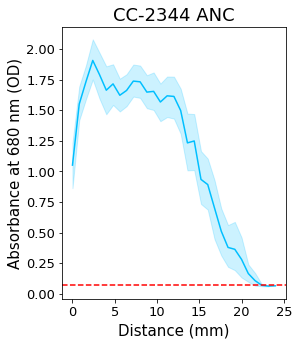

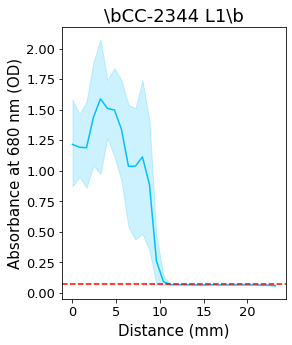

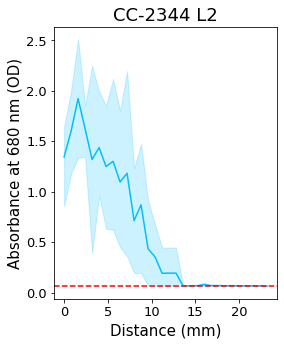

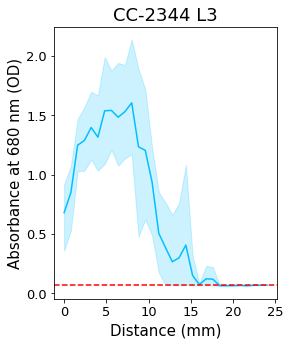

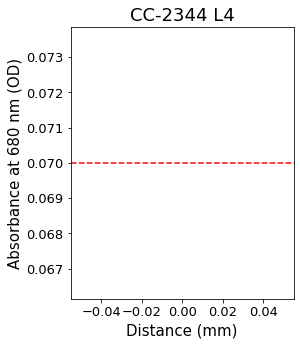

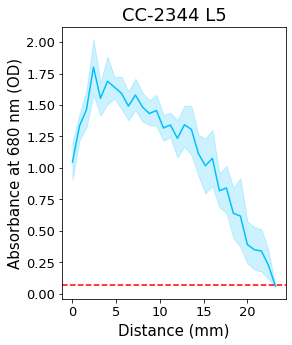

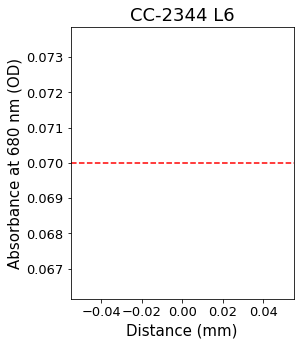

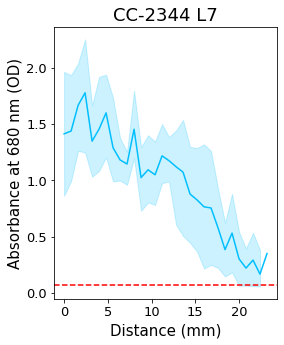

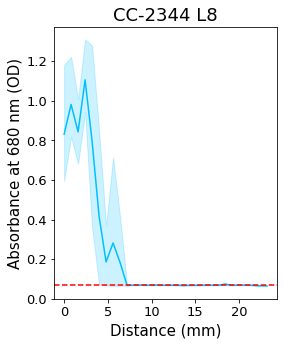

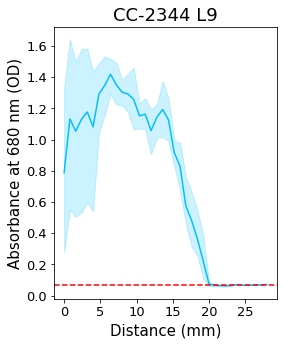

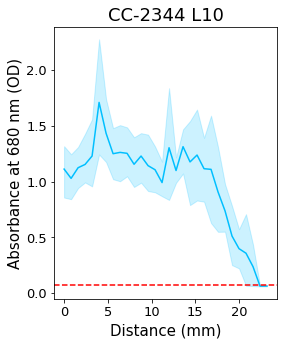

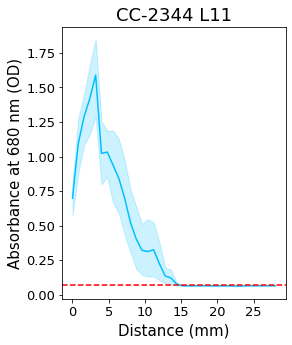

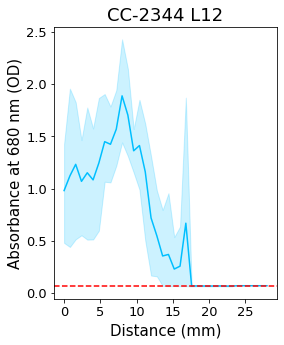

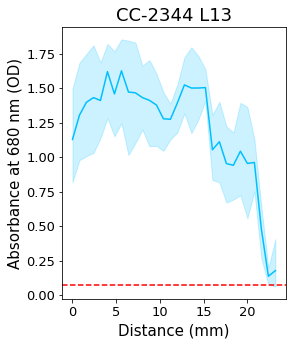

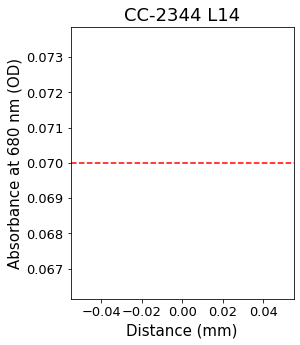

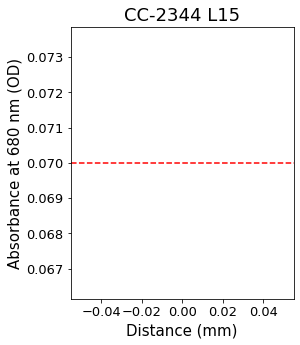

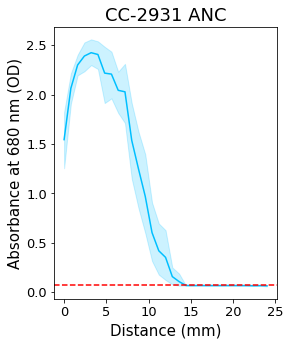

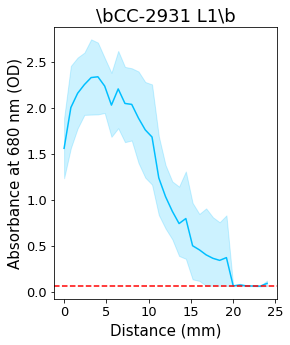

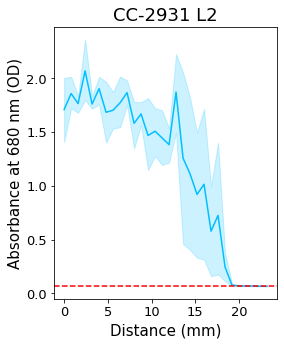

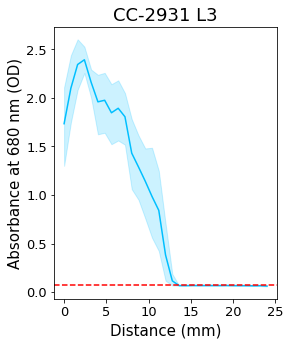

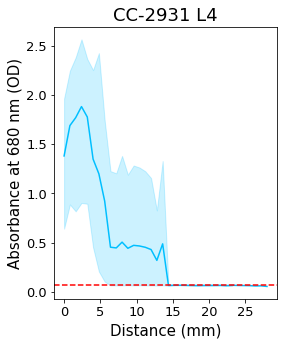

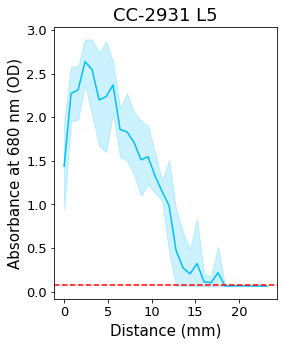

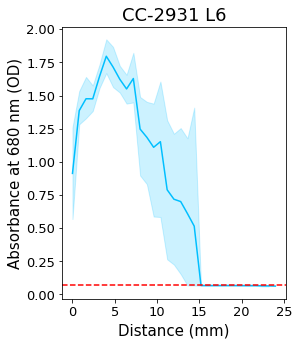

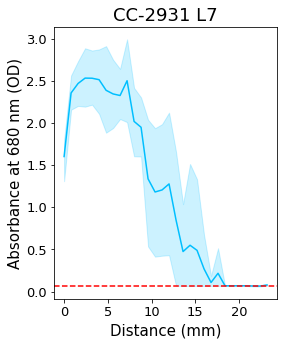

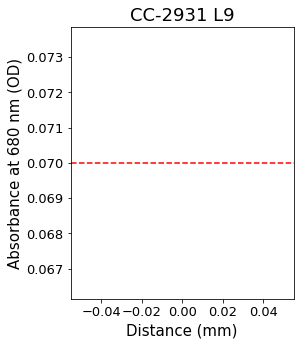

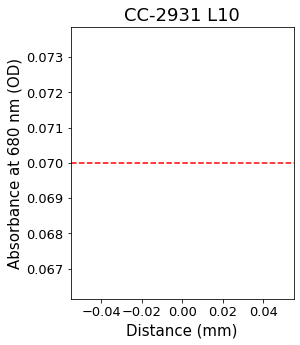

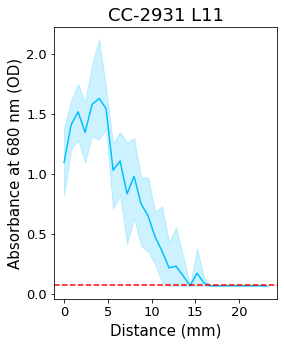

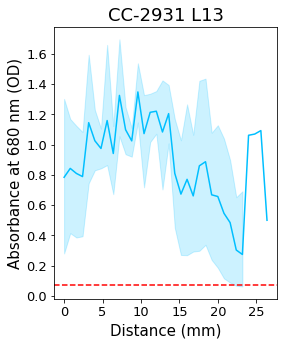

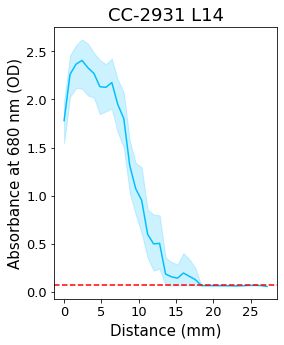

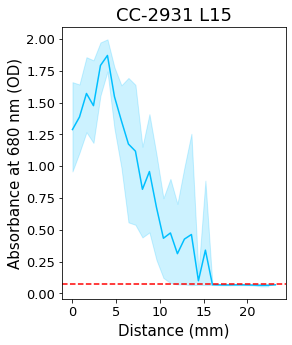

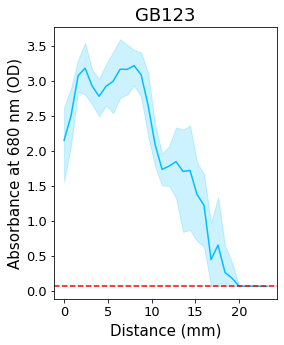

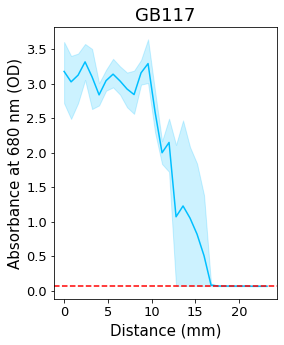

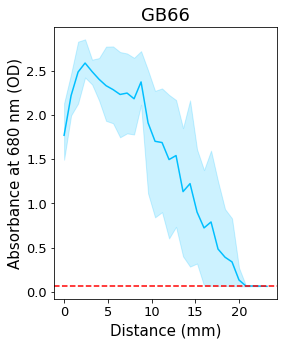

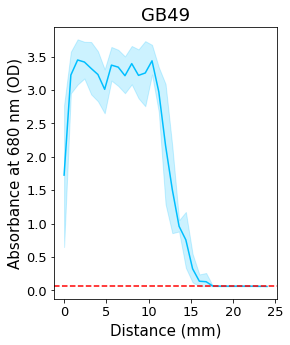

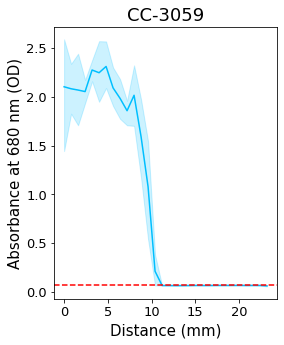

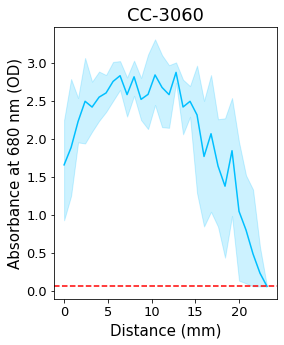

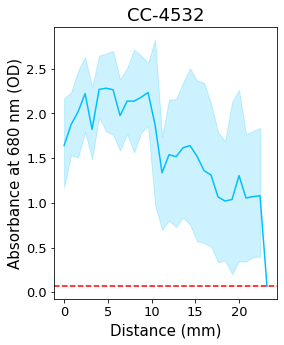

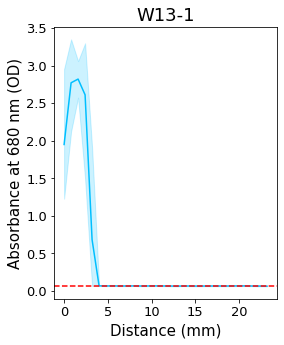

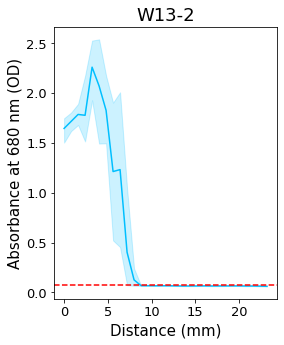

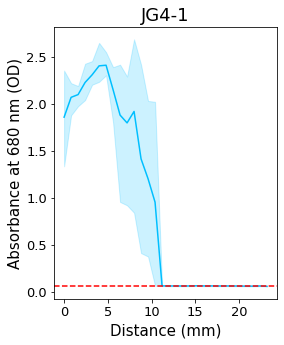

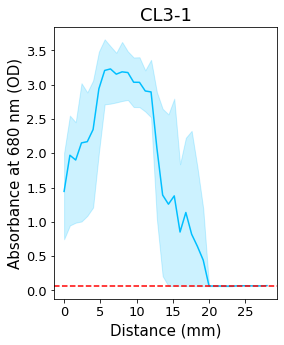

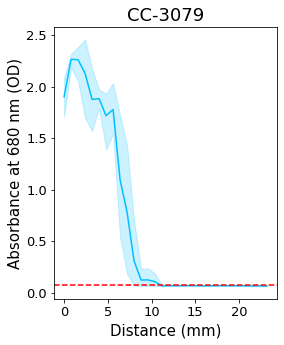

In [37]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
import numpy as np

CC2344 = ['CC-2344 ANC', r"\bCC-2344 L1\b", "CC-2344 L2", "CC-2344 L3", "CC-2344 L4", "CC-2344 L5", "CC-2344 L6", "CC-2344 L7", "CC-2344 L8", "CC-2344 L9", "CC-2344 L10", "CC-2344 L11", "CC-2344 L12", "CC-2344 L13", "CC-2344 L14", "CC-2344 L15"]
CC2931 = ['CC-2931 ANC', r"\bCC-2931 L1\b", "CC-2931 L2", "CC-2931 L3", "CC-2931 L4", "CC-2931 L5", "CC-2931 L6", "CC-2931 L7", "CC-2931 L9", "CC-2931 L10", "CC-2931 L11", "CC-2931 L13", "CC-2931 L14", "CC-2931 L15"]
NI = ['GB123', 'GB117', 'GB66', 'GB49', 'CC-3059', 'CC-3060', 'CC-4532', 'W13-1', 'W13-2', 'JG4-1', 'CL3-1', 'CC-3079']

for strain in CC2344 + CC2931 + NI:
    a = mot1[mot1.columns[mot1.columns.str.contains(strain)]]
    b = mot2[mot2.columns[mot2.columns.str.contains(strain)]]
    c = mot3[mot3.columns[mot3.columns.str.contains(strain)]] 
    d = mot4[mot4.columns[mot4.columns.str.contains(strain)]]
    e = mot5[mot5.columns[mot5.columns.str.contains(strain)]]
    f = ni[ni.columns[ni.columns.str.contains(strain)]]
    
    combined = pd.concat([a, b, c, d, e, f], axis = 1).reset_index()
    combined = pd.melt(combined, id_vars = ['index'], value_vars = combined.columns[1:])
    combined['index'] = combined['index'] * 0.8 # Each well represents a 0.8 mm increase
    
    plt.figure(figsize = (4, 5))
    sns.lineplot(data = combined, x = 'index', y = 'value', color = 'deepskyblue')
    plt.title(strain, fontsize = 18)
    plt.xlabel('Distance (mm)', fontsize = 15)
    plt.xticks(fontsize = 13)
    plt.ylabel("Absorbance at 680 nm (OD)", fontsize = 15)
    plt.yticks(fontsize = 13)
    plt.axhline(y = 0.07, color = 'red', linestyle = 'dashed')
#     plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/Lineplot_5days/Lineplot_' + strain + '.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

## Boxplot - Distribution of Maximum Distance

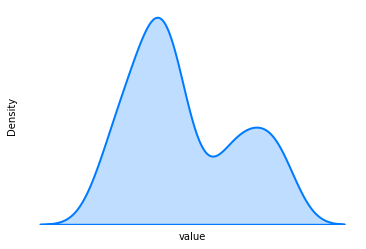

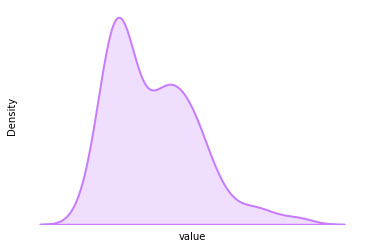

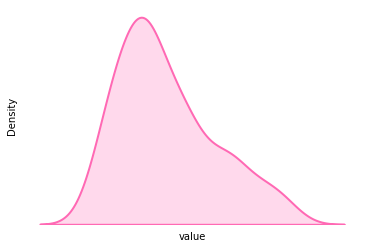

In [38]:
df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')
CC2344_data = df.loc[df['type'].isin(['CC-2344 MA', 'CC-2344 ANC'])]
ax = sns.kdeplot(CC2344_data['value'], legend = True, color = "#007BFF", fill = "#A5D8FF", linewidth=2)
# Remove all four borders
sns.despine(top=True, right=True, left=True, bottom=True)
ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
plt.show()

plt.figure()
CC2931_data = df.loc[df['type'].isin(['CC-2931 MA', 'CC-2931 ANC'])]
ax = sns.kdeplot(CC2931_data['value'], legend = True, color = "#C77CFF", fill = "#E5DBFF", linewidth=2)
sns.despine(top=True, right=True, left=True, bottom=True)
ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
plt.show()

plt.figure()
NI_data = df.loc[df['type'] == 'NI']
ax = sns.kdeplot(NI_data['value'], legend = True, color = "hotpink", fill = 'lightpink', linewidth=2)
sns.despine(top=True, right=True, left=True, bottom=True)
ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
plt.show()

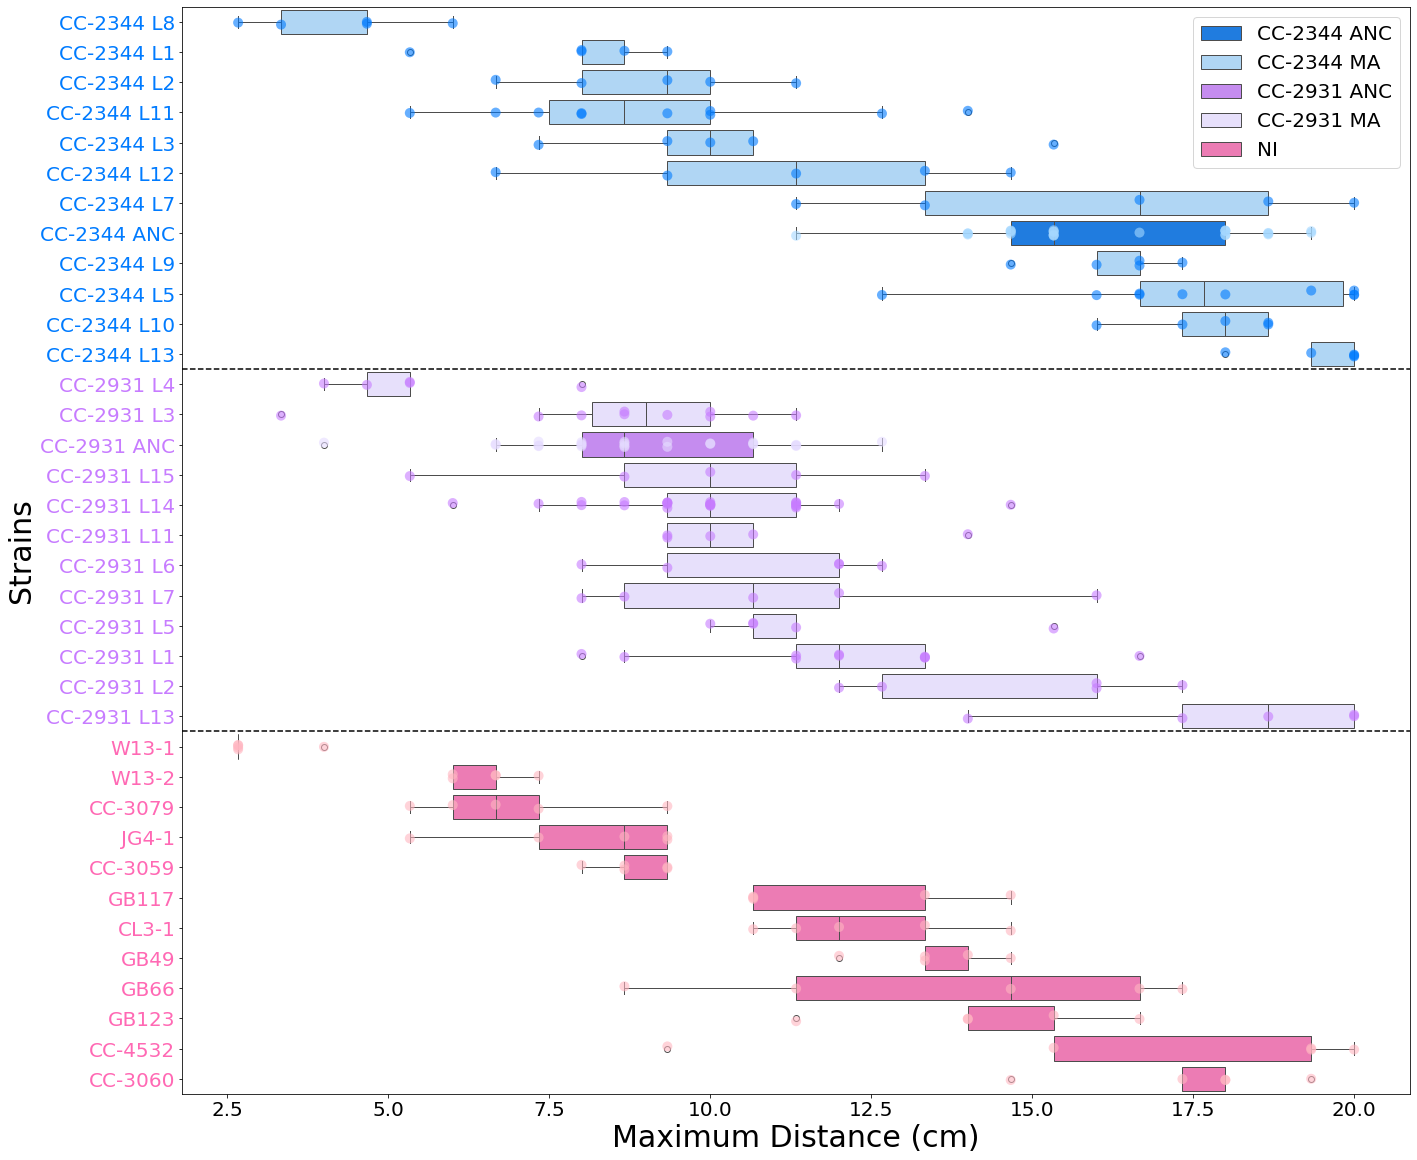

In [43]:
average_max = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/average_maximum_distance3.csv', delimiter = '\t')
df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')

CC2344_order = list(average_max.loc[average_max['type'] == 'CC-2344'].sort_values(by = ['mean'], ascending = True)['strain'])
CC2931_order = list(average_max.loc[average_max['type'] == 'CC-2931'].sort_values(by = ['mean'], ascending = True)['strain'])
NI_order = list(average_max.loc[average_max['type'] == 'NI'].sort_values(by = ['mean'], ascending = True)['strain'])

order = CC2344_order + CC2931_order + NI_order

plt.figure(figsize = (22, 20))
candy_pastels = ["#007BFF", "#A5D8FF", "#C77CFF", "#E5DBFF", "hotpink"]
candy_pastels2 = ["#A5D8FF", "#007BFF", "#E5DBFF", "#C77CFF", 'lightpink']
ax = sns.boxplot(data = df.loc[df['distance'] == 'Maximum Distance'], y = 'strain', x = 'value', hue = 'type', legend = True, palette = candy_pastels, order = order)
sns.stripplot(x = "value", y= "strain", data = df.loc[df['distance'] == 'Maximum Distance'], hue = 'type', color=".25", size = 10, jitter=True, alpha=0.6, palette = candy_pastels2, legend = False)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('Maximum Distance (cm)', fontsize = 30)
plt.ylabel('Strains', fontsize = 30)
plt.axhline(11.5, color = 'black', linestyle = 'dashed')
plt.axhline(23.5, color = 'black', linestyle = 'dashed')
plt.legend(fontsize= 20)
           
#### Adding colours to vertical tick labels ####
c1 = [color for color in ["#007BFF"] for _ in range(12)]
c2 = [color for color in ["#C77CFF"] for _ in range(12)]
c3 = [color for color in ["hotpink"] for _ in range(12)]
colours = c1 + c2 + c3

for i, label in enumerate(ax.get_yticklabels()):
    label.set_color(colours[i])
    
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/Distribution_rate_strains.pdf', dpi = 1600, format = 'pdf')

## Boxplot - Distribution of Weighted Average

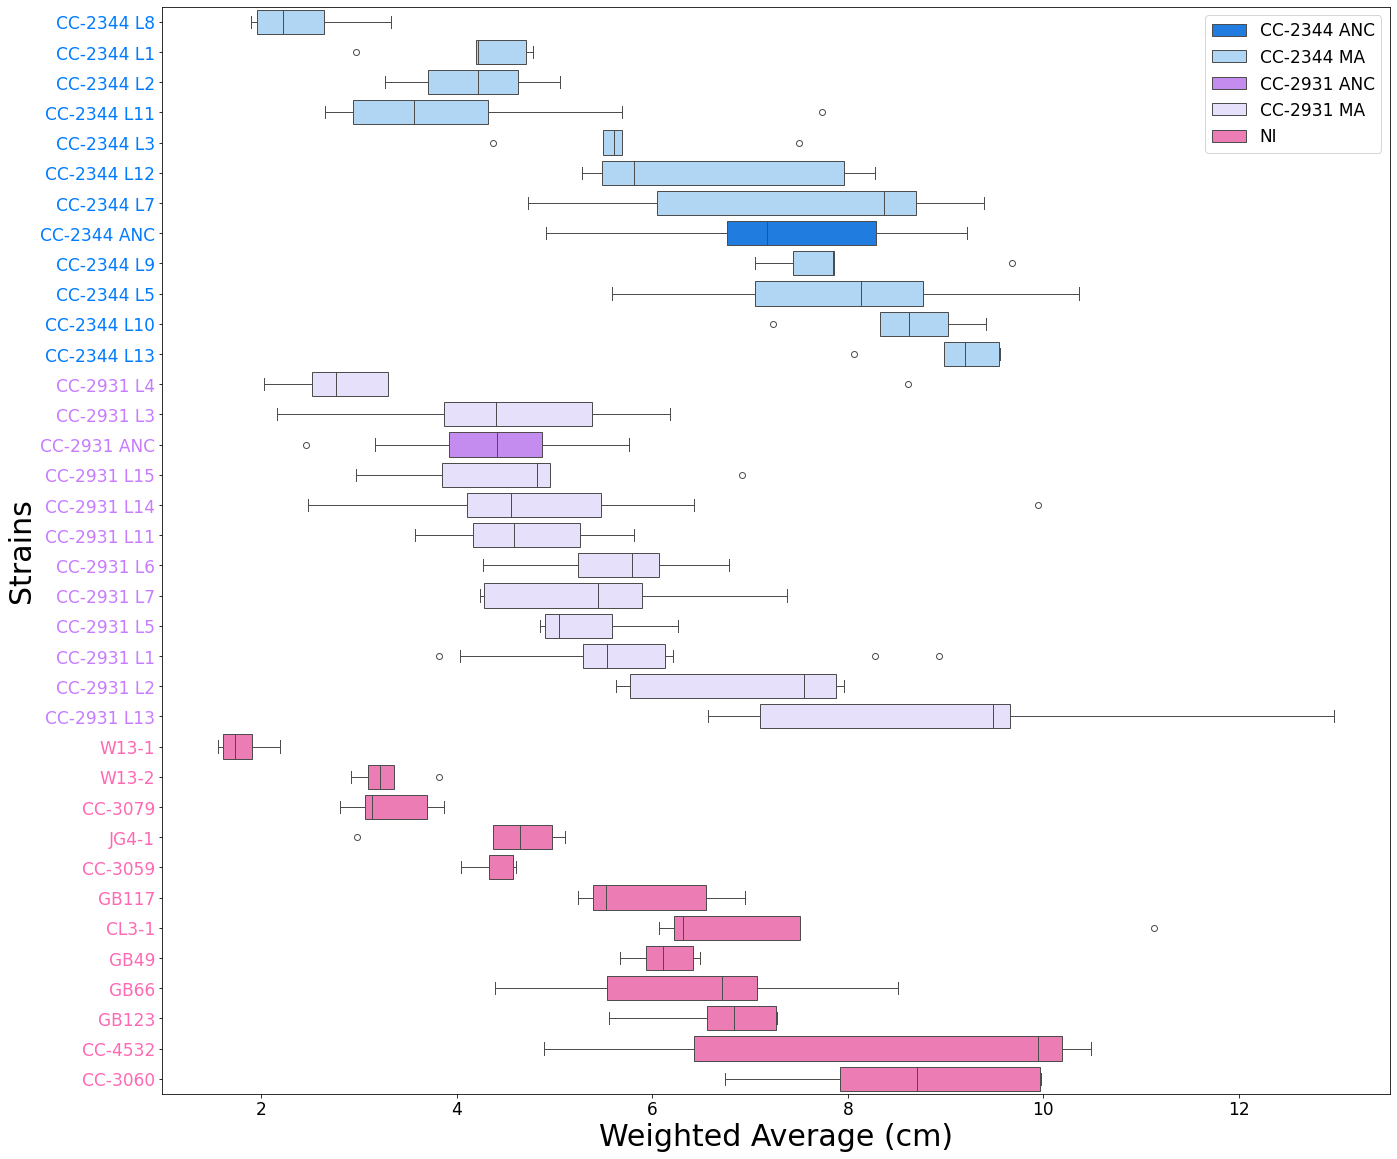

In [45]:
plt.figure(figsize = (22, 20))
ax = sns.boxplot(data = df.loc[df['distance'] == 'Weighted Average'], y = 'strain', x = 'value', hue = 'type', legend = True, order = order, palette = candy_pastels)
ax.legend_.set_frame_on(False)
plt.xticks(fontsize = 17)
plt.yticks(fontsize = 17)
plt.xlabel('Weighted Average (cm)', fontsize = 30)
plt.ylabel('Strains', fontsize = 30)
plt.legend(fontsize= 17)

#### Adding colours to vertical tick labels ####
c1 = [color for color in ["#007BFF"] for _ in range(12)]
c2 = [color for color in ["#C77CFF"] for _ in range(12)]
c3 = [color for color in ["hotpink"] for _ in range(12)]
colours = c1 + c2 + c3

for i, label in enumerate(ax.get_yticklabels()):
    label.set_color(colours[i])

## Violinplot - Distribution of Phototactic Rate across Strain Types

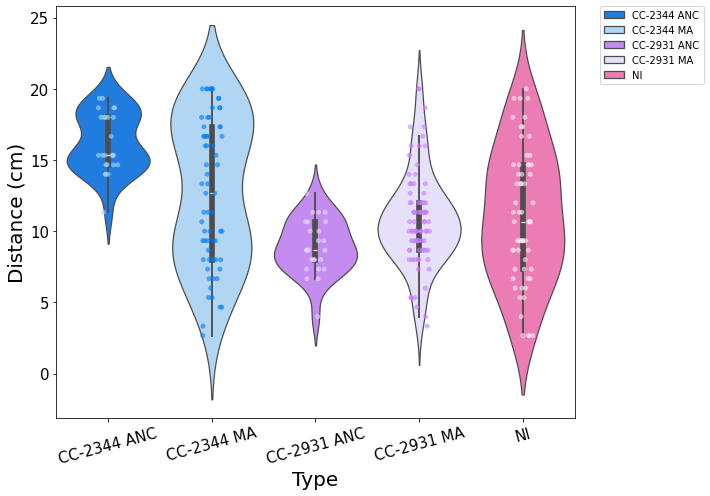

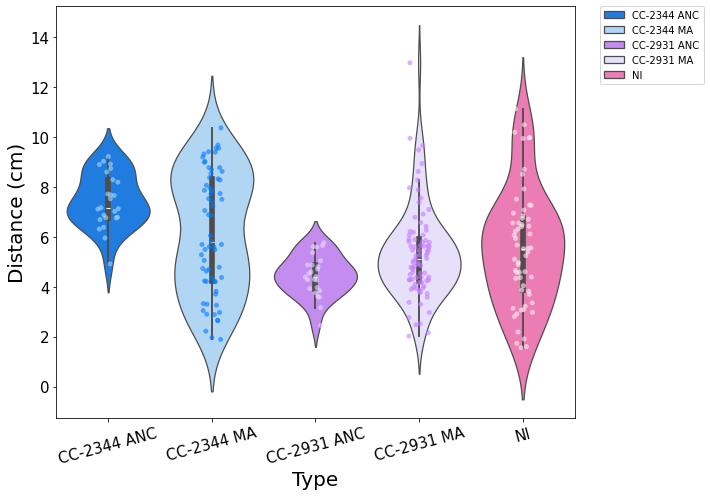

In [47]:
plt.figure(figsize = (10, 7))
candy_pastels2 = ["#A5D8FF", "#007BFF", "#E5DBFF", "#C77CFF", 'lavenderblush']
data = df.loc[df['distance'] == 'Maximum Distance']
sns.violinplot(data = data, hue = 'type', y = 'value', x = 'type', legend = True, palette = candy_pastels)
sns.stripplot(x = "type", y= "value", data = data, hue = 'type', color=".25", size = 5, jitter=True, alpha=0.6, palette = candy_pastels2, legend = False)
# plt.title('Distribution of Maximum Distance', fontsize = 20)
plt.xticks(fontsize = 15, rotation = 15)
plt.yticks(fontsize = 15)
plt.xlabel('Type', fontsize = 20)
plt.ylabel('Distance (cm)', fontsize = 20)
plt.legend(fontsize= 12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

# Use tight_layout so the legend isn't cut off when saving
plt.tight_layout()
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/overall_distribution_max_dis3_edited.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

plt.figure(figsize = (10, 7))
data = df.loc[df['distance'] == 'Weighted Average']
sns.violinplot(data = data, hue = 'type', y = 'value', x = 'type', legend = True, palette = candy_pastels)
sns.stripplot(x = "type", y= "value", data = data, hue = 'type', color=".25", size = 5, jitter=True, alpha=0.6, palette = candy_pastels2, legend = False)
# plt.title('Distribution of Weighted Average', fontsize = 20)
plt.xticks(fontsize = 15, rotation = 15)
plt.yticks(fontsize = 15)
plt.xlabel('Type', fontsize = 20)
plt.ylabel('Distance (cm)', fontsize = 20)
plt.legend(fontsize= 12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/overall_distribution_weighted_dis.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

# Statistical Difference Testing

## Levene's Test

In [48]:
# stat, p = stats.levene(a, b, c)
df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')
average_df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/average_maximum_distance3.csv', delimiter = '\t')

average_df2 = average_df.loc[~average_df['strain'].isin(['CC-2344 ANC', 'CC-2931 ANC'])]
df2 = df.loc[df['distance'] == 'Maximum Distance']

#### comparing ANC vs CC2931 MA, CC-2344 MA, NI ####
stat, p = stats.levene(df2.loc[df2['broad_type'] == 'ANC']['value'], average_df2.loc[average_df2['type'].isin(['NI', 'CC-2931', 'CC-2344'])]['mean'])
print(stat, p)

#### comparing CC-2344 ANC vs CC2931 MA, CC-2344 MA, NI ####
stat, p = stats.levene(df2.loc[df2['type'] == 'CC-2344 ANC']['value'], average_df2.loc[average_df2['type'].isin(['NI', 'CC-2931', 'CC-2344'])]['mean'])
print(stat, p)

#### comparing CC-2931 ANC vs CC2931 MA, CC-2344 MA, NI ####
stat, p = stats.levene(df2.loc[df2['type'] == 'CC-2931 ANC']['value'], average_df2.loc[average_df2['type'].isin(['NI', 'CC-2931', 'CC-2344'])]['mean'])
print(stat, p)

#### comparing CC-2931 MA, CC-2344 MA ####
stat, p = stats.levene(average_df2.loc[average_df2['type'] == 'CC-2931']['mean'], average_df2.loc[average_df2['type'] == 'CC-2344']['mean'])
print(stat, p)

#### comparing CC-2931 MA, CC-2344 MA, NI ####
stat, p = stats.levene(average_df.loc[(average_df['type'] == 'CC-2931') & (average_df['strain'] != 'CC-2931 ANC')]['mean'], average_df.loc[(average_df['type'] == 'CC-2344') & (average_df['strain'] != 'CC-2344 ANC')]['mean'], average_df.loc[(average_df['type'] == 'NI')|(average_df['strain'] == 'CC-2931 ANC')|(average_df['strain'] == 'CC-2344 ANC')]['mean'])
print(stat, p)

0.46498376306845 0.49722553689041715
8.278382249070116 0.005636433896409703
11.604885507097237 0.0012119775971930831
3.618877544984558 0.07162690684153455
2.017543125998654 0.14905946595106742


## Kruskal-Wallis Test

In [49]:
cc2931_ma = average_df2.loc[average_df2['type'] == 'CC-2931']['mean']
cc2344_ma = average_df2.loc[average_df2['type'] == 'CC-2344']['mean']
ma = pd.concat([cc2931_ma, cc2344_ma], axis = 0)
ni = average_df2.loc[(average_df2['type'] == 'NI') ]['mean']
ni_with_anc = average_df.loc[(average_df['type'] == 'NI')|(average_df['strain'] == 'CC-2931 ANC')|(average_df['strain'] == 'CC-2344 ANC')]['mean']
print(stat, p)
cc2931_anc = df2[df2['type'] == 'CC-2931 ANC']['value']
cc2344_anc = df2[df2['type'] == 'CC-2344 ANC']['value']
anc = pd.concat([cc2931_anc, cc2344_anc], axis = 0)

#### Mann Whitney U Test ####
display(stats.mannwhitneyu(cc2344_anc, cc2344_ma))

display(stats.mannwhitneyu(cc2931_anc, cc2931_ma))

#### Kruskal-Wallis Test ####
stat, p = stats.kruskal(cc2344_ma, cc2931_ma)
print(stat, p)

stat, p = stats.kruskal(cc2344_ma, cc2931_ma, ni_with_anc)
print(stat, p)

stat, p = stats.kruskal(cc2931_anc, cc2344_anc)
print(stat, p)

stat, p = stats.kruskal(ni, cc2931_anc, cc2344_anc)
print(stat, p)

stat, p = stats.kruskal(cc2344_anc, cc2344_ma, cc2931_anc, cc2931_ma)
print(stat, p)

stat, p = stats.kruskal(cc2344_anc, cc2344_ma, cc2931_anc, cc2931_ma, ni)
print(stat, p)

stat, p = stats.kruskal(ma, ni, anc)
print(stat, p)

#### One-way ANOVA ####
f_val, p_val = stats.f_oneway(ma, ni, anc)
print(f_val, p_val)
f_val, p_val = stats.f_oneway(cc2344_ma, cc2344_anc)
print(f_val, p_val)
f_val, p_val = stats.f_oneway(cc2931_ma, cc2931_anc)
print(f_val, p_val)

2.017543125998654 0.14905946595106742


MannwhitneyuResult(statistic=192.0, pvalue=0.06241260780084012)

MannwhitneyuResult(statistic=68.5, pvalue=0.018341722505186366)

0.155315870570105 0.6935062176271403
0.5719414146615386 0.7512846227565179
36.37971994205695 1.6238408600120758e-09
38.93000686286894 3.519301053376949e-09
39.119848509257274 1.637101892864602e-08
40.83319568612856 2.910279493468397e-08
1.1562924348722936 0.5609372590377326
0.6603565617018894 0.5194260716630987
9.367354868496545 0.0042931294277211065
6.718635228132289 0.013962135350355129


**Note**: All tests below use Maximum Distance as the response variable, as it appears to capture more variation across strains. It is also possible to run each test for Weighted Average, but it will end up even more crowded.

## Parametric

A one-way ANOVA where strain is a fixed factor and variable (ie. week) is a blocking/nuisance factor. A significant difference is detected, after which Tukey's Honestly Significant Difference is performed to highlight pairwise differences.

The results suggest 276 significant pairwise differences.

                  sum_sq     df          F        PR(>F)
C(strain)    3939.304615   35.0  24.083434  2.510887e-57
C(variable)    21.264957    4.0   1.137552  3.396896e-01
Residual     1028.148376  220.0        NaN           NaN


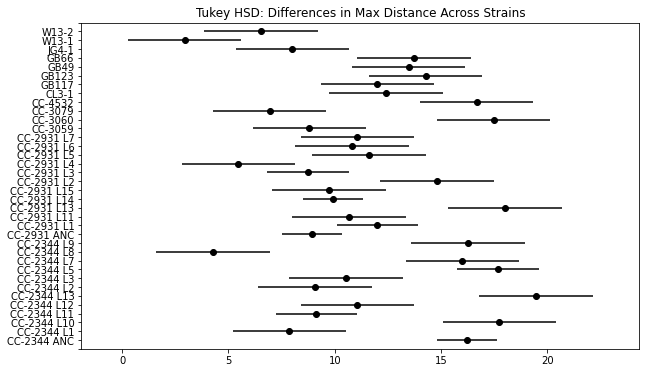

276
          group1       group2  meandiff   p-adj    lower   upper  reject
0    CC-2344 ANC   CC-2344 L1   -8.3467  0.0000 -12.4721 -4.2213    True
2    CC-2344 ANC  CC-2344 L11   -7.0800  0.0000 -10.2308 -3.9292    True
3    CC-2344 ANC  CC-2344 L12   -5.1467  0.0012  -9.2721 -1.0213    True
5    CC-2344 ANC   CC-2344 L2   -7.1467  0.0000 -11.2721 -3.0213    True
6    CC-2344 ANC   CC-2344 L3   -5.6800  0.0001  -9.8054 -1.5546    True
..           ...          ...       ...     ...      ...     ...     ...
622         GB49        W13-1  -10.5333  0.0000 -15.8592 -5.2075    True
623         GB49        W13-2   -6.9333  0.0005 -12.2592 -1.6075    True
624         GB66        JG4-1   -5.7333  0.0178 -11.0592 -0.4075    True
625         GB66        W13-1  -10.8000  0.0000 -16.1259 -5.4741    True
626         GB66        W13-2   -7.2000  0.0002 -12.5259 -1.8741    True

[276 rows x 7 columns]


In [64]:
df = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/motility_assay_3.csv', delimiter = '\t')

subset = df[df['distance'] == 'Maximum Distance']
%R -i subset

# Fit the ANOVA model
model = smf.ols('value ~ C(strain) + C(variable)', data=subset).fit()

# Run ANOVA table
anova_table = anova_lm(model, typ=2)  # typ=2 matches R's default
print(anova_table)

# Run Tukey HSD for strain
tukey = pairwise_tukeyhsd(endog=subset['value'], groups=subset['strain'], alpha=0.05)

# Plot
tukey.plot_simultaneous()
plt.title("Tukey HSD: Differences in Max Distance Across Strains")
plt.show()

# Convert to DataFrame
tukey_df = pd.DataFrame(data=tukey.summary().data[1:],  # skip header row
                        columns=tukey.summary().data[0])  # use header row

# Filter where reject is True
significant = tukey_df[tukey_df['reject'] == True]
print(len(significant))
print(significant)

In [54]:
significant.loc[significant['group1'] == 'CC-2931 ANC']

,group1,group2,meandiff,p-adj,lower,upper,reject
356,CC-2931 ANC,CC-2931 L13,9.0667,0.0000,4.9413,13.1921,True
359,CC-2931 ANC,CC-2931 L2,5.8667,0.0001,1.7413,9.9921,True
366,CC-2931 ANC,CC-3060,8.5333,0.0000,4.4079,12.6587,True
368,CC-2931 ANC,CC-4532,7.7333,0.0000,3.6079,11.8587,True
371,CC-2931 ANC,GB123,5.3333,0.0006,1.2079,9.4587,True
372,CC-2931 ANC,GB49,4.5333,0.0129,0.4079,8.6587,True
373,CC-2931 ANC,GB66,4.8000,0.0048,0.6746,8.9254,True
375,CC-2931 ANC,W13-1,-6.0000,0.0000,-10.1254,-1.8746,True


In [55]:
significant.loc[significant['group1'] == 'CC-2344 ANC']

,group1,group2,meandiff,p-adj,lower,upper,reject
0,CC-2344 ANC,CC-2344 L1,-8.3467,0.0000,-12.4721,-4.2213,True
2,CC-2344 ANC,CC-2344 L11,-7.0800,0.0000,-10.2308,-3.9292,True
3,CC-2344 ANC,CC-2344 L12,-5.1467,0.0012,-9.2721,-1.0213,True
5,CC-2344 ANC,CC-2344 L2,-7.1467,0.0000,-11.2721,-3.0213,True
6,CC-2344 ANC,CC-2344 L3,-5.6800,0.0001,-9.8054,-1.5546,True
9,CC-2344 ANC,CC-2344 L8,-11.9467,0.0000,-16.0721,-7.8213,True
11,CC-2344 ANC,CC-2931 ANC,-7.2800,0.0000,-9.6618,-4.8982,True
12,CC-2344 ANC,CC-2931 L1,-4.2133,0.0003,-7.3642,-1.0625,True
13,CC-2344 ANC,CC-2931 L11,-5.5467,0.0002,-9.6721,-1.4213,True
15,CC-2344 ANC,CC-2931 L14,-6.2933,0.0000,-8.6751,-3.9115,True


In [56]:
%%R
model <- aov(value ~ strain + Error(variable), data = subset)
summary(model)


Error: variable
          Df Sum Sq Mean Sq F value Pr(>F)
Residuals  4  21.27   5.316               

Error: Within
           Df Sum Sq Mean Sq F value Pr(>F)    
strain     35   3939  112.55   24.08 <2e-16 ***
Residuals 220   1028    4.67                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


                  sum_sq     df          F        PR(>F)
C(variable)    21.264957    4.0   0.325468  8.607525e-01
C(type)       867.589965    4.0  13.278802  7.906144e-10
Residual     4099.863027  251.0        NaN           NaN


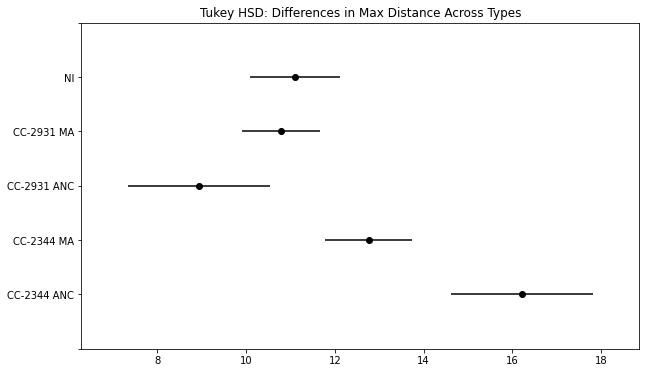

6
        group1       group2  meandiff   p-adj    lower   upper  reject
0  CC-2344 ANC   CC-2344 MA   -3.4544  0.0029  -6.0536 -0.8551    True
1  CC-2344 ANC  CC-2931 ANC   -7.2800  0.0000 -10.4040 -4.1560    True
2  CC-2344 ANC   CC-2931 MA   -5.4369  0.0000  -7.9498 -2.9240    True
3  CC-2344 ANC           NI   -5.1133  0.0000  -7.7425 -2.4841    True
4   CC-2344 MA  CC-2931 ANC   -3.8256  0.0007  -6.4249 -1.2264    True
5   CC-2344 MA   CC-2931 MA   -1.9825  0.0251  -3.8024 -0.1626    True


In [57]:
# Fit the ANOVA model
model = smf.ols('value ~ C(variable) + C(type)', data=subset).fit()

# Run ANOVA table
anova_table = anova_lm(model, typ=2)  # typ=2 matches R's default
print(anova_table)

# Run Tukey HSD for strain
tukey = pairwise_tukeyhsd(endog=subset['value'], groups=subset['type'], alpha=0.05)

# Plot
tukey.plot_simultaneous()
plt.title("Tukey HSD: Differences in Max Distance Across Types")
plt.show()

# Convert to DataFrame
tukey_df = pd.DataFrame(data=tukey.summary().data[1:],  # skip header row
                        columns=tukey.summary().data[0])  # use header row

# Filter where reject is True
significant = tukey_df[tukey_df['reject'] == True]
print(len(significant))
print(significant)

                    sum_sq     df         F    PR(>F)
C(variable)      21.264957    4.0  0.274094  0.894539
C(broad_type)    60.343134    2.0  1.555581  0.213079
Residual       4907.109858  253.0       NaN       NaN


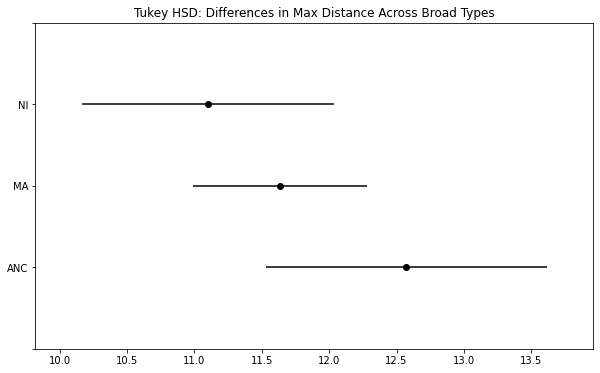

0
Empty DataFrame
Columns: [group1, group2, meandiff, p-adj, lower, upper, reject]
Index: []


In [58]:
# Fit the ANOVA model
model = smf.ols('value ~ C(variable) + C(broad_type)', data=subset).fit()

# Run ANOVA table
anova_table = anova_lm(model, typ=2)  # typ=2 matches R's default
print(anova_table)

# Run Tukey HSD for strain
tukey = pairwise_tukeyhsd(endog=subset['value'], groups=subset['broad_type'], alpha=0.05)

# Plot
tukey.plot_simultaneous()
plt.title("Tukey HSD: Differences in Max Distance Across Broad Types")
plt.show()

# Convert to DataFrame
tukey_df = pd.DataFrame(data=tukey.summary().data[1:],  # skip header row
                        columns=tukey.summary().data[0])  # use header row

# Filter where reject is True
significant = tukey_df[tukey_df['reject'] == True]
print(len(significant))
print(significant)

## Non-Parametric

Pairwise Permutation Test (like Tukey/Dunn), asking “For each pair of strains: Is the difference in mean value greater than expected by chance?”

1. Compute the observed difference in group means
2. Combine the values into a single pool
3. Randomly shuffle the values and split into two new groups
4. Compute permuted difference in means
5. Repeat this many times (e.g. 10,000)
     - With 36 strains → 630 pairwise tests, each with 10,000 permutations = 6.3 million permutations
7. P-value = how many times the permuted difference was ≥ observed
8. Adjust p-values for multiple testing (FDR or Bonferroni)

The results suggest 363/630 pairwise strains are significantly different from each other.

In [65]:
# Check for different number of observations

df_subset = df[df['distance'] == 'Maximum Distance'][['strain', 'value']].copy()

strains = df_subset['strain'].unique()
results = []

n_permutations = 10000

for s1, s2 in combinations(strains, 2):
    v1 = df_subset[df_subset['strain'] == s1]['value'].values
    v2 = df_subset[df_subset['strain'] == s2]['value'].values
    observed_diff = np.abs(np.mean(v1) - np.mean(v2))
    
    combined = np.concatenate([v1, v2])
    count = 0
    for _ in range(n_permutations):
        np.random.shuffle(combined)
        new_v1 = combined[:len(v1)]
        new_v2 = combined[len(v1):]
        perm_diff = np.abs(np.mean(new_v1) - np.mean(new_v2))
        if perm_diff >= observed_diff:
            count += 1
    
    p_value = count / n_permutations
    results.append({'strain1': s1, 'strain2': s2, 'mean_diff': observed_diff, 'p_value': p_value})

pairwise_results = pd.DataFrame(results)
display(len(pairwise_results))
pairwise_results['p_adj'] = multipletests(pairwise_results['p_value'], method='fdr_bh')[1]
pairwise_results.head()

significant_pairs = pairwise_results[pairwise_results['p_adj'] < 0.05]
print(len(significant_pairs))
print(significant_pairs[['strain1', 'strain2', 'mean_diff', 'p_value', 'p_adj']].to_string(index=False))

630

363
    strain1     strain2  mean_diff  p_value    p_adj
CC-2344 ANC  CC-2344 L2   7.146667   0.0001 0.001212
CC-2344 ANC CC-2344 L11   7.080000   0.0000 0.000000
CC-2344 ANC CC-2344 L13   3.253333   0.0017 0.009562
CC-2344 ANC CC-2344 L12   5.146667   0.0003 0.002662
CC-2344 ANC  CC-2344 L1   8.346667   0.0000 0.000000
CC-2344 ANC  CC-2344 L8  11.946667   0.0000 0.000000
CC-2344 ANC  CC-2344 L3   5.680000   0.0001 0.001212
CC-2344 ANC CC-2931 ANC   7.280000   0.0000 0.000000
CC-2344 ANC  CC-2931 L6   5.413333   0.0001 0.001212
CC-2344 ANC  CC-2931 L5   4.613333   0.0007 0.005011
CC-2344 ANC  CC-2931 L1   4.213333   0.0000 0.000000
CC-2344 ANC CC-2931 L11   5.546667   0.0000 0.000000
CC-2344 ANC  CC-2931 L4  10.746667   0.0000 0.000000
CC-2344 ANC  CC-2931 L3   7.480000   0.0000 0.000000
CC-2344 ANC CC-2931 L14   6.293333   0.0000 0.000000
CC-2344 ANC  CC-2931 L7   5.146667   0.0000 0.000000
CC-2344 ANC CC-2931 L15   6.480000   0.0000 0.000000
CC-2344 ANC        GB49   2.746667   0.007

# Data - Carbone et al. 2016

In [12]:
carbone = pd.read_excel('/research/projects/chlamydomonas/PhototacticRate/data/Carbone_2016.xlsx', sheet_name='Dataset S1', skiprows = 1)
display(carbone.loc[(carbone['Sex'] == 'Male') & (carbone['Age (Weeks)'] == 1)]['Mean Phototaxis Score'].describe())
display(carbone.loc[(carbone['Sex'] == 'Female') & (carbone['Age (Weeks)'] == 1)]['Mean Phototaxis Score'].describe())
display(carbone.loc[(carbone['Sex'] == 'Male') & (carbone['Age (Weeks)'] == 2)]['Mean Phototaxis Score'].describe())
display(carbone.loc[(carbone['Sex'] == 'Female') & (carbone['Age (Weeks)'] == 2)]['Mean Phototaxis Score'].describe())
display(carbone.loc[(carbone['Sex'] == 'Male') & (carbone['Age (Weeks)'] == 4)]['Mean Phototaxis Score'].describe())
display(carbone.loc[(carbone['Sex'] == 'Female') & (carbone['Age (Weeks)'] == 4)]['Mean Phototaxis Score'].describe())

count    191.000000
mean       4.574780
std        1.321882
min        1.227586
25%        3.701601
50%        4.462687
75%        5.327021
max        7.584507
Name: Mean Phototaxis Score, dtype: float64

count    191.000000
mean       4.299878
std        1.219071
min        1.538462
25%        3.432490
50%        4.168675
75%        5.079329
max        7.669118
Name: Mean Phototaxis Score, dtype: float64

count    191.000000
mean       4.744262
std        1.421281
min        1.371681
25%        3.654140
50%        4.661017
75%        5.918060
max        7.514563
Name: Mean Phototaxis Score, dtype: float64

count    191.000000
mean       4.200617
std        1.361636
min        1.344828
25%        3.212074
50%        4.119266
75%        5.314054
max        7.173077
Name: Mean Phototaxis Score, dtype: float64

count    185.000000
mean       3.411904
std        1.225157
min        1.000000
25%        2.550725
50%        3.417219
75%        4.209302
max        6.368421
Name: Mean Phototaxis Score, dtype: float64

count    185.000000
mean       2.886639
std        1.103070
min        1.000000
25%        2.138686
50%        2.697183
75%        3.601504
max        6.680851
Name: Mean Phototaxis Score, dtype: float64